In [1]:
# ============================================================
# Cell 1 — All Imports
# ============================================================
import pandas as pd
import numpy as np
import glob, os, time, pickle, warnings
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, precision_recall_curve, average_precision_score
)
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 20)
print("All imports OK")

All imports OK


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# ============================================================
# Cell 2 — Defensive CSV Loading
# Fixes: encoding artifacts, unnamed columns, 96-col bug
# ============================================================
os.chdir("/Users/harishnivasagam/Downloads/MachineLearningCVE")

files = glob.glob("*.csv")
print(f"Files found: {len(files)}")

frames = []
for f in files:
    try:
        tmp = pd.read_csv(
            f,
            encoding='utf-8',
            encoding_errors='replace',   # replace bad bytes, don't crash
            low_memory=False
        )
        # Strip whitespace from column names
        tmp.columns = tmp.columns.str.strip()
        # Drop any fully unnamed/empty columns
        tmp = tmp.loc[:, ~tmp.columns.str.contains('^Unnamed')]
        # Drop columns that are entirely NaN
        tmp.dropna(axis=1, how='all', inplace=True)
        frames.append(tmp)
        print(f"  OK  {f:<60} {tmp.shape}")
    except Exception as e:
        print(f"  FAIL {f}: {e}")

df = pd.concat(frames, ignore_index=True)
df.columns = df.columns.str.strip()

print(f"\nMerged shape: {df.shape}")
print(f"Columns: {df.shape[1]}")
print("\nLabel distribution:")
print(df['Label'].value_counts())

Files found: 8
  OK  Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv  (288602, 79)
  OK  Monday-WorkingHours.pcap_ISCX.csv                            (529918, 79)
  OK  Friday-WorkingHours-Morning.pcap_ISCX.csv                    (191033, 79)
  OK  Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv         (286467, 79)
  OK  Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv             (225745, 79)
  OK  Tuesday-WorkingHours.pcap_ISCX.csv                           (445909, 79)
  OK  Wednesday-workingHours.pcap_ISCX.csv                         (692703, 79)
  OK  Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv       (170366, 79)

Merged shape: (2830743, 79)
Columns: 79

Label distribution:
Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowlor

In [4]:
import os, glob, pandas as pd

# Check 1: where are we?
print("Current directory:", os.getcwd())

# Check 2: what files does glob see?
files = glob.glob("*.csv")
print(f"CSV files found: {len(files)}")
for f in files:
    print(f"  {f}")

# Check 3: read just ONE file raw, no processing
if files:
    tmp = pd.read_csv(files[0], nrows=5, low_memory=False)
    print(f"\nFirst file shape (5 rows): {tmp.shape}")
    print(f"Columns: {tmp.shape[1]}")
    print(f"First 3 col names: {tmp.columns[:3].tolist()}")
    print(f"\nNaN count in 5 rows: {tmp.isna().sum().sum()}")
    print(f"Sample Label values: {tmp.iloc[:, -1].tolist()}")
else:
    print("NO CSV FILES FOUND — os.chdir() has not run or wrong path")

Current directory: /Users/harishnivasagam/Downloads/MachineLearningCVE
CSV files found: 8
  Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
  Monday-WorkingHours.pcap_ISCX.csv
  Friday-WorkingHours-Morning.pcap_ISCX.csv
  Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
  Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
  Tuesday-WorkingHours.pcap_ISCX.csv
  Wednesday-workingHours.pcap_ISCX.csv
  Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv

First file shape (5 rows): (5, 79)
Columns: 79
First 3 col names: [' Destination Port', ' Flow Duration', ' Total Fwd Packets']

NaN count in 5 rows: 0
Sample Label values: ['BENIGN', 'BENIGN', 'BENIGN', 'BENIGN', 'BENIGN']


In [5]:
df.shape

(2830743, 79)

In [6]:
# ============================================================
# Cell 3 — Robust Cleaning (FINAL CORRECT VERSION)
# Handles CIC-IDS column mismatch issue properly
# ============================================================

import numpy as np

# Step 1: capture labels safely
assert 'Label' in df.columns, "Label column missing!"
original_labels = df['Label'].copy()
print(f"original_labels captured: {len(original_labels):,} rows")

# Step 2: strip column names (VERY IMPORTANT for CIC dataset)
df.columns = df.columns.str.strip()

# Step 3: keep only numeric columns + Label
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
df = df[num_cols + ['Label']]

# Step 4: replace Inf → NaN
df[num_cols] = df[num_cols].replace([np.inf, -np.inf], np.nan)

# ============================================================
# 🔥 CORE FIX: Drop columns with too many NaNs
# ============================================================

nan_ratio = df[num_cols].isna().mean()

# drop columns with >40% NaNs (tunable)
bad_cols = nan_ratio[nan_ratio > 0.4].index.tolist()

print(f"\nDropping {len(bad_cols)} high-NaN columns")

df = df.drop(columns=bad_cols)

# recompute numeric columns
num_cols = df.select_dtypes(include=[np.number]).columns

# ============================================================
# 🔥 DO NOT DROP ALL ROWS — use threshold
# ============================================================

# keep rows with at least 90% valid data
valid_threshold = int(0.9 * len(num_cols))

before = len(df)

df = df.dropna(thresh=valid_threshold)

after = len(df)

print(f"\nRows before: {before:,}")
print(f"Rows after : {after:,}")
print(f"Rows removed: {before - after:,}")

# ============================================================
# Fill remaining NaNs (safe for tree models)
# ============================================================

df[num_cols] = df[num_cols].fillna(0)

# ============================================================
# Reset index safely
# ============================================================

df = df.reset_index(drop=True)
original_labels = original_labels.loc[df.index].reset_index(drop=True)

print(f"\nFinal shape: {df.shape}")

# ============================================================
# Safety check
# ============================================================

assert df.shape[0] > 100_000, f"Too few rows after cleaning: {df.shape[0]}"

print("✅ Assertion passed — df is healthy")

original_labels captured: 2,830,743 rows

Dropping 0 high-NaN columns

Rows before: 2,830,743
Rows after : 2,830,743
Rows removed: 0

Final shape: (2830743, 79)
✅ Assertion passed — df is healthy


In [7]:
# ============================================================
# Cell 4 — Binary Label Encoding
# ============================================================
print(f"df shape before encoding: {df.shape}")

df['Label'] = df['Label'].apply(lambda x: 0 if x.strip() == 'BENIGN' else 1)

print("Binary label distribution:")
print(df['Label'].value_counts())
print(f"\nAttack ratio: {df['Label'].mean()*100:.2f}%")
assert df['Label'].sum() > 0, "No attack rows found — check Label column"

df shape before encoding: (2830743, 79)
Binary label distribution:
Label
0    2273097
1     557646
Name: count, dtype: int64

Attack ratio: 19.70%


In [8]:
# ============================================================
# Cell 5 — Train/Test Split
# Leakage fix: Destination Port dropped before split
# ============================================================
print(f"df shape: {df.shape}")

# Drop label + leaking port columns
cols_to_drop = ['Label', 'Destination Port', 'Dst Port',
                'Flow ID', 'Source IP', 'Destination IP',
                'Source Port', 'Timestamp']

X = df.drop(columns=cols_to_drop, errors='ignore')
y = df['Label']

print(f"Features: {X.shape[1]}")
print(f"Samples : {X.shape[0]:,}")
print(f"y distribution:\n{y.value_counts()}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(f"\nTrain : {X_train.shape}")
print(f"Test  : {X_test.shape}")
print(f"Train attack ratio: {y_train.mean()*100:.2f}%")
print(f"Test  attack ratio: {y_test.mean()*100:.2f}%")

df shape: (2830743, 79)
Features: 77
Samples : 2,830,743
y distribution:
Label
0    2273097
1     557646
Name: count, dtype: int64

Train : (2264594, 77)
Test  : (566149, 77)
Train attack ratio: 19.70%
Test  attack ratio: 19.70%


In [9]:
# ============================================================
# Cell 6 — Correlation Pruning (|r| > 0.95)
# ============================================================
corr_matrix = X_train.corr(numeric_only=True).abs()
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)
to_drop = [col for col in upper.columns if any(upper[col] > 0.95)]

X_train_reduced = X_train.drop(columns=to_drop)
X_test_reduced  = X_test.drop(columns=to_drop)

print(f"Dropped (|r|>0.95) : {len(to_drop)}")
print(f"Features remaining : {X_train_reduced.shape[1]}")

Dropped (|r|>0.95) : 23
Features remaining : 54


In [10]:
# ============================================================
# Cell 7 — RF Importance → 20 Golden Features
# ============================================================
rf = RandomForestClassifier(
    n_estimators=100, max_depth=5,
    random_state=42, n_jobs=-1
)
rf.fit(X_train_reduced, y_train)

importances = pd.Series(
    rf.feature_importances_,
    index=X_train_reduced.columns
).sort_values(ascending=False)

TOP_N = 20
golden_features = importances.head(TOP_N).index.tolist()

X_train_final = X_train_reduced[golden_features]
X_test_final  = X_test_reduced[golden_features]

print("20 Golden Features (payload-agnostic):")
for i, f in enumerate(golden_features, 1):
    print(f"  {i:2d}. {f}  ({importances[f]:.4f})")
print(f"\nFinal shape: {X_train_final.shape}")

20 Golden Features (payload-agnostic):
   1. Packet Length Variance  (0.1498)
   2. Bwd Packet Length Max  (0.1085)
   3. Max Packet Length  (0.0707)
   4. Total Length of Fwd Packets  (0.0635)
   5. Packet Length Mean  (0.0615)
   6. Fwd Packet Length Mean  (0.0395)
   7. Fwd IAT Std  (0.0374)
   8. Fwd Packet Length Max  (0.0371)
   9. Bwd Header Length  (0.0278)
  10. Fwd Header Length  (0.0272)
  11. PSH Flag Count  (0.0268)
  12. Flow IAT Std  (0.0253)
  13. Init_Win_bytes_backward  (0.0246)
  14. Flow IAT Mean  (0.0233)
  15. Bwd Packet Length Min  (0.0228)
  16. Flow IAT Max  (0.0225)
  17. min_seg_size_forward  (0.0212)
  18. Min Packet Length  (0.0183)
  19. Init_Win_bytes_forward  (0.0178)
  20. act_data_pkt_fwd  (0.0167)

Final shape: (2264594, 20)


In [11]:
# ============================================================
# Cell 8 — XGBoost Edge Classifier
# ============================================================
scale_pos_weight = y_train.value_counts()[0] / y_train.value_counts()[1]
print(f"scale_pos_weight: {scale_pos_weight:.3f}")

xgb_model = XGBClassifier(
    objective='binary:logistic',
    max_depth=4,
    learning_rate=0.1,
    n_estimators=200,
    subsample=0.8,
    colsample_bytree=0.6,
    scale_pos_weight=scale_pos_weight,
    tree_method='hist',
    random_state=42,
    n_jobs=-1,
    eval_metric='logloss'
)

xgb_model.fit(X_train_final, y_train)
print("Training complete.")

scale_pos_weight: 4.076
Training complete.


In [12]:
# ============================================================
# Cell 9 — Evaluation
# ============================================================
y_pred = xgb_model.predict(X_test_final)
y_prob = xgb_model.predict_proba(X_test_final)[:, 1]

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")

Confusion Matrix:
[[452402   2218]
 [   189 111340]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9996    0.9951    0.9973    454620
           1     0.9805    0.9983    0.9893    111529

    accuracy                         0.9957    566149
   macro avg     0.9900    0.9967    0.9933    566149
weighted avg     0.9958    0.9957    0.9958    566149

ROC-AUC: 0.9998


Saved: shap_beeswarm.png


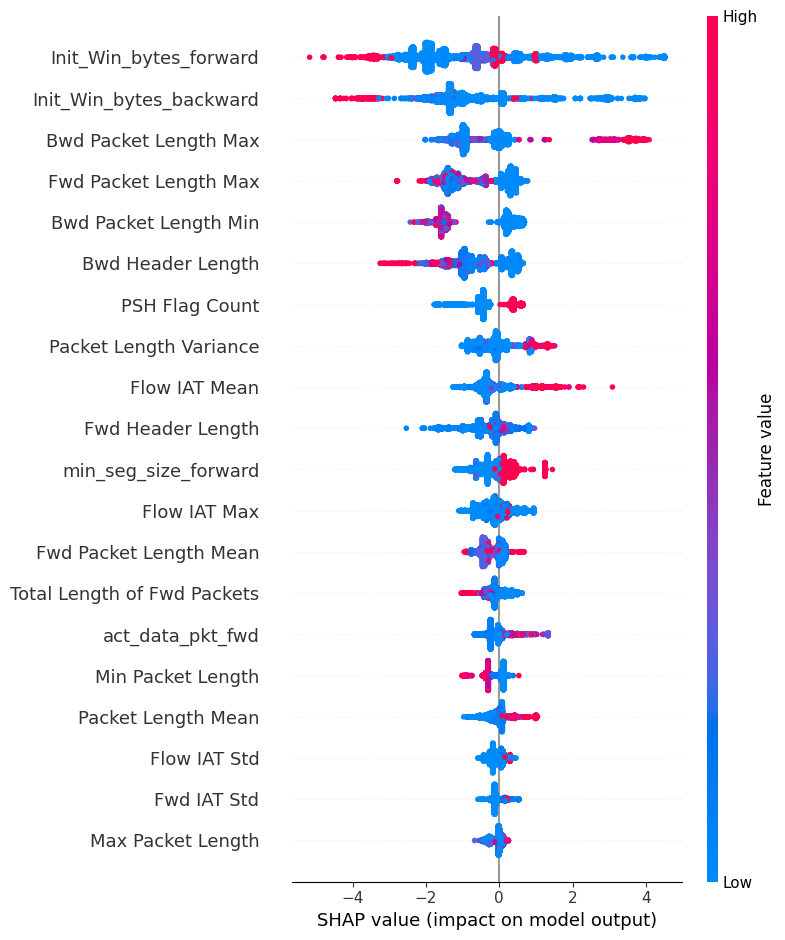

Saved: shap_bar_mean_abs.png


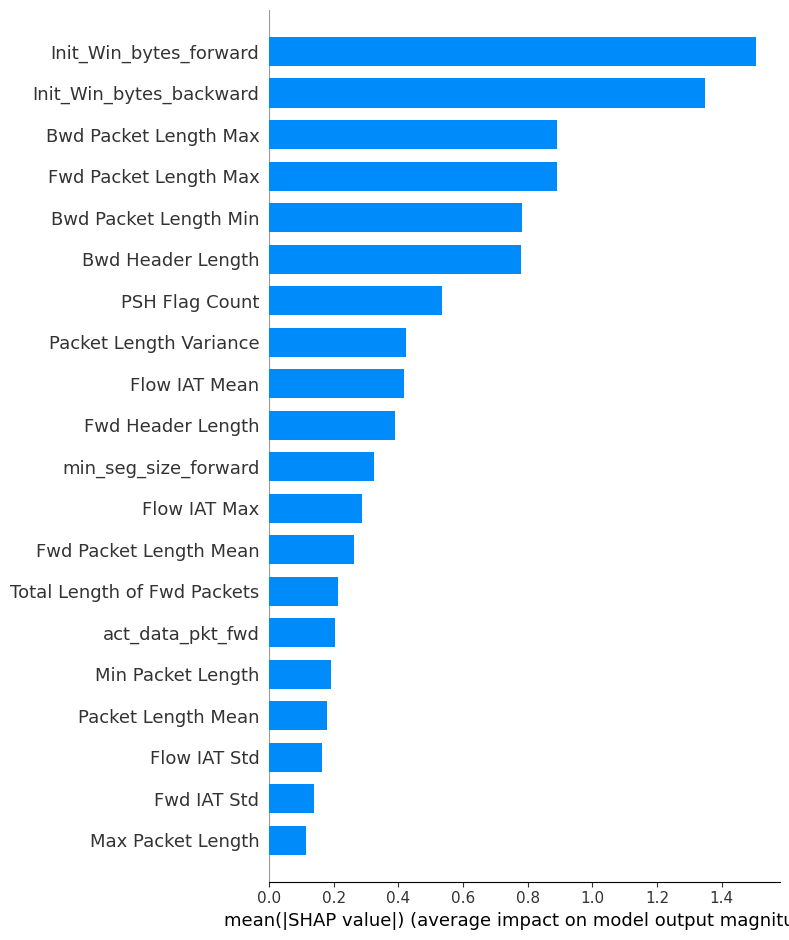

Saved: shap_waterfall.png


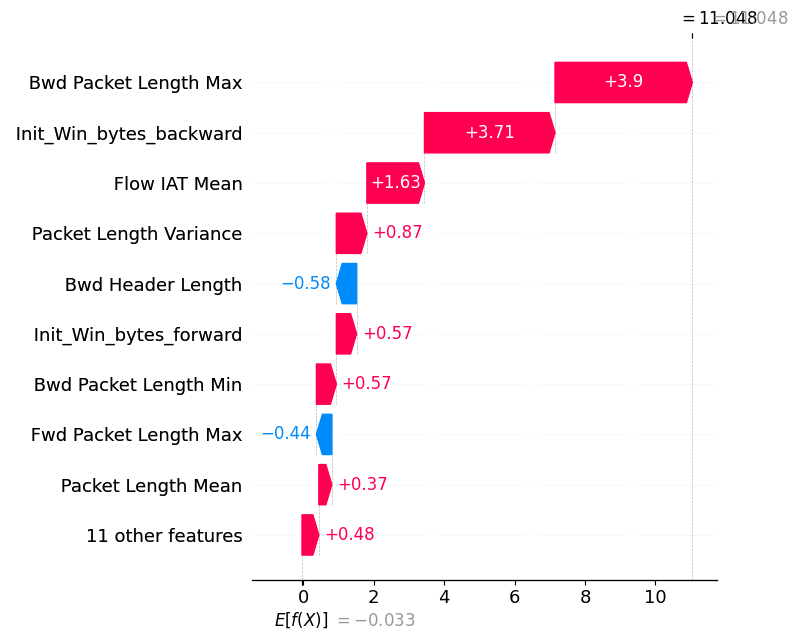

In [13]:
# ============================================================
# Cell 10 — SHAP Explainability (all 3 plots)
# ============================================================
explainer = shap.TreeExplainer(xgb_model)
N = min(5000, X_test_final.shape[0])
X_subset = X_test_final.iloc[:N]
shap_values = explainer.shap_values(X_subset)

# Beeswarm
plt.figure(figsize=(8, 10))
shap.summary_plot(shap_values, X_subset, show=False)
plt.tight_layout()
plt.savefig("shap_beeswarm.png", dpi=300, bbox_inches='tight')
print("Saved: shap_beeswarm.png")
plt.show()

# Mean |SHAP| Bar
plt.figure(figsize=(8, 10))
shap.summary_plot(shap_values, X_subset, plot_type='bar', show=False)
plt.tight_layout()
plt.savefig("shap_bar_mean_abs.png", dpi=300, bbox_inches='tight')
print("Saved: shap_bar_mean_abs.png")
plt.show()

# Local Waterfall — single attack flow
pos_idx = y_test[y_test == 1].index[0]
sample_flow = X_test_final.loc[[pos_idx]]
sv = explainer.shap_values(sample_flow)
plt.figure(figsize=(10, 6))
shap.plots._waterfall.waterfall_legacy(
    explainer.expected_value, sv[0],
    sample_flow.iloc[0], show=False
)
plt.tight_layout()
plt.savefig("shap_waterfall.png", dpi=300, bbox_inches='tight')
print("Saved: shap_waterfall.png")
plt.show()

Saved: pr_curve.png


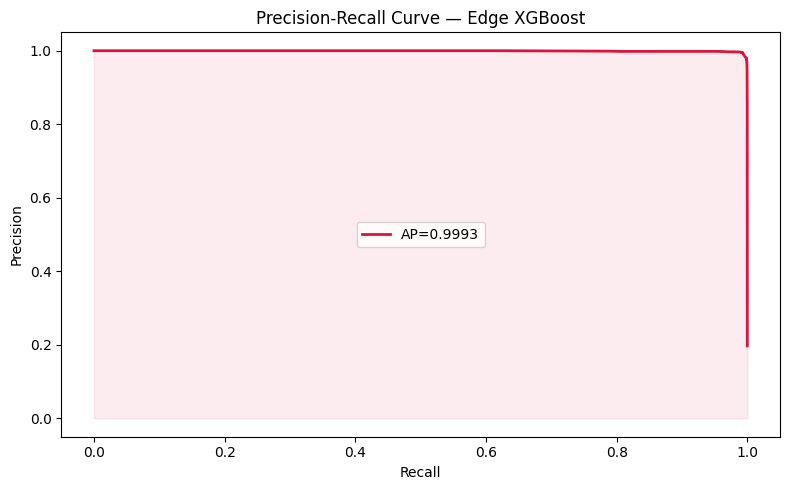

Optimal threshold: 0.6587
Precision: 0.9949  Recall: 0.9927
  Batch     1 → 0.522 ms
  Batch    10 → 0.470 ms
  Batch    50 → 0.494 ms
  Batch   100 → 0.536 ms
  Batch   500 → 0.778 ms
  Batch  1000 → 1.124 ms
Saved: latency_curve.png


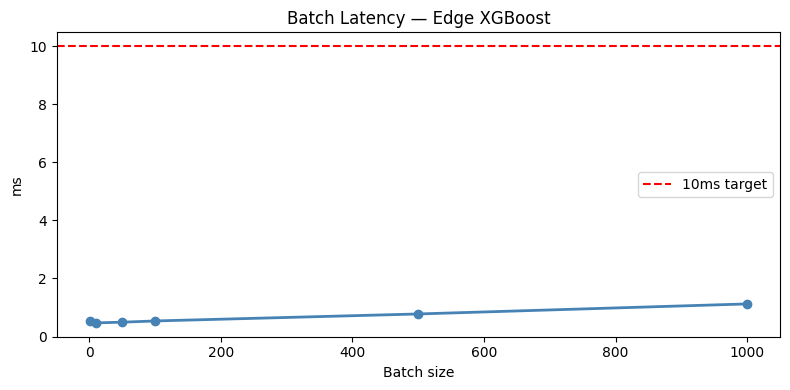

Saved: confidence_dist.png


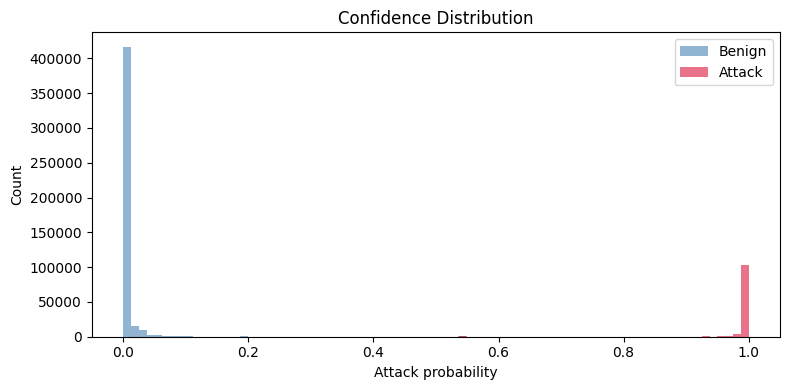

In [14]:
# ============================================================
# Cell 11 — Extended Analysis (Blueprint Metrics)
# ============================================================

# --- PR Curve ---
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)
ap = average_precision_score(y_test, y_prob)
plt.figure(figsize=(8, 5))
plt.plot(recall, precision, color='crimson', lw=2, label=f'AP={ap:.4f}')
plt.fill_between(recall, precision, alpha=0.08, color='crimson')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('Precision-Recall Curve — Edge XGBoost')
plt.legend(); plt.tight_layout()
plt.savefig('pr_curve.png', dpi=300, bbox_inches='tight')
print("Saved: pr_curve.png"); plt.show()

f1_scores = 2*precision[:-1]*recall[:-1]/(precision[:-1]+recall[:-1]+1e-9)
best_idx  = f1_scores.argmax()
print(f"Optimal threshold: {thresholds[best_idx]:.4f}")
print(f"Precision: {precision[best_idx]:.4f}  Recall: {recall[best_idx]:.4f}")

# --- Batch Latency ---
batch_sizes = [1, 10, 50, 100, 500, 1000]
latencies   = []
for b in batch_sizes:
    batch = X_test_final.iloc[:b]
    for _ in range(20): xgb_model.predict(batch)
    start = time.perf_counter()
    for _ in range(200): xgb_model.predict(batch)
    avg_ms = (time.perf_counter()-start)/200*1000
    latencies.append(avg_ms)
    print(f"  Batch {b:>5} → {avg_ms:.3f} ms")

plt.figure(figsize=(8, 4))
plt.plot(batch_sizes, latencies, marker='o', color='steelblue', lw=2)
plt.axhline(y=10, color='red', linestyle='--', label='10ms target')
plt.xlabel('Batch size'); plt.ylabel('ms')
plt.title('Batch Latency — Edge XGBoost')
plt.legend(); plt.tight_layout()
plt.savefig('latency_curve.png', dpi=300, bbox_inches='tight')
print("Saved: latency_curve.png"); plt.show()

# --- Confidence Distribution ---
plt.figure(figsize=(8, 4))
plt.hist(y_prob[y_test==0], bins=80, alpha=0.6, color='steelblue', label='Benign')
plt.hist(y_prob[y_test==1], bins=80, alpha=0.6, color='crimson', label='Attack')
plt.xlabel('Attack probability'); plt.ylabel('Count')
plt.title('Confidence Distribution')
plt.legend(); plt.tight_layout()
plt.savefig('confidence_dist.png', dpi=300, bbox_inches='tight')
print("Saved: confidence_dist.png"); plt.show()


=== PER-ATTACK DETECTION RATE ===
               Attack Type  Total Flows  Detected  Missed  Detection Rate %
                Heartbleed            2         2       0            100.00
                  PortScan        31954     31952       2             99.99
                      DDoS        25599     25582      17             99.93
                  DoS Hulk        46075     46028      47             99.90
               FTP-Patator         1593      1591       2             99.87
             DoS slowloris         1146      1142       4             99.65
               SSH-Patator         1189      1183       6             99.50
          DoS Slowhttptest         1081      1070      11             98.98
             DoS GoldenEye         2069      2045      24             98.84
  Web Attack � Brute Force          319       307      12             96.24
          Web Attack � XSS          129       122       7             94.57
                       Bot          362       313    

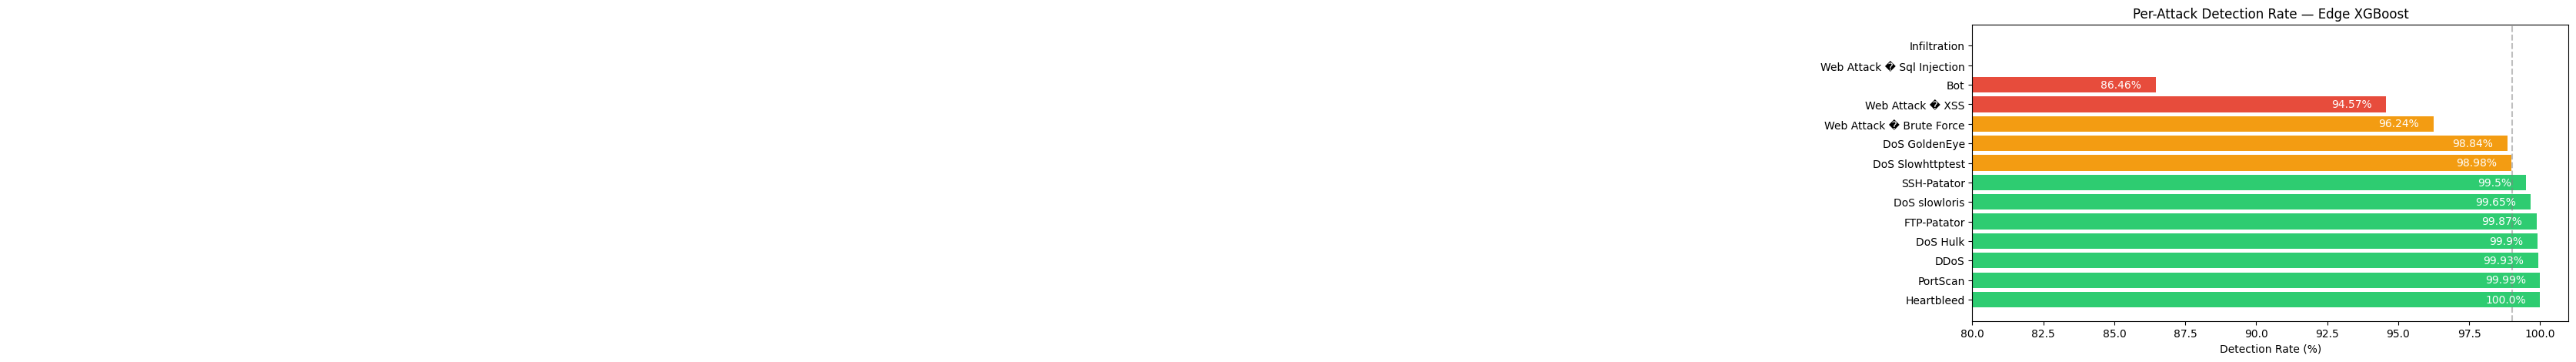

In [15]:
# ============================================================
# Cell 12 — Per-Attack Detection Rate (Index Lookup)
# ============================================================
test_original_labels = pd.Series(
    original_labels.values, index=range(len(original_labels))
).iloc[list(range(len(y_test)))]

# Simpler approach: rebuild from scratch using position
y_test_arr   = y_test.values
y_pred_arr   = y_pred
orig_arr     = original_labels.values   # numpy array, positional

# Get test set positions
test_indices = list(X_test_final.index)
orig_test    = np.array([orig_arr[i] for i in test_indices])

results = []
for attack in sorted(set(orig_test[y_test_arr == 1])):
    mask     = (orig_test == attack)
    detected = int(y_pred_arr[mask].sum())
    total    = int(mask.sum())
    results.append({
        'Attack Type':      attack,
        'Total Flows':      total,
        'Detected':         detected,
        'Missed':           total - detected,
        'Detection Rate %': round(detected/total*100, 2)
    })

results_df = pd.DataFrame(results).sort_values('Detection Rate %', ascending=False)
print("\n=== PER-ATTACK DETECTION RATE ===")
print(results_df.to_string(index=False))
results_df.to_csv('per_attack_detection.csv', index=False)

plt.figure(figsize=(10, 5))
colors = ['#2ecc71' if r>=99 else '#f39c12' if r>=95 else '#e74c3c'
          for r in results_df['Detection Rate %']]
bars = plt.barh(results_df['Attack Type'], results_df['Detection Rate %'], color=colors)
plt.axvline(x=99, color='gray', linestyle='--', alpha=0.5)
plt.xlabel('Detection Rate (%)'); plt.xlim(80, 101)
plt.title('Per-Attack Detection Rate — Edge XGBoost')
for bar, val in zip(bars, results_df['Detection Rate %']):
    plt.text(bar.get_width()-0.5, bar.get_y()+bar.get_height()/2,
             f'{val}%', va='center', ha='right', color='white', fontsize=10)
plt.tight_layout()
plt.savefig('per_attack_detection.png', dpi=300, bbox_inches='tight')
print("Saved: per_attack_detection.png"); plt.show()


=== PER-ATTACK DETECTION RATE ===
               Attack Type  Total Flows  Detected  Missed  Detection Rate %
                Heartbleed            2         2       0            100.00
                  PortScan        31954     31952       2             99.99
                      DDoS        25599     25582      17             99.93
                  DoS Hulk        46075     46028      47             99.90
               FTP-Patator         1593      1591       2             99.87
             DoS slowloris         1146      1142       4             99.65
               SSH-Patator         1189      1183       6             99.50
          DoS Slowhttptest         1081      1070      11             98.98
             DoS GoldenEye         2069      2045      24             98.84
  Web Attack � Brute Force          319       307      12             96.24
          Web Attack � XSS          129       122       7             94.57
                       Bot          362       313    

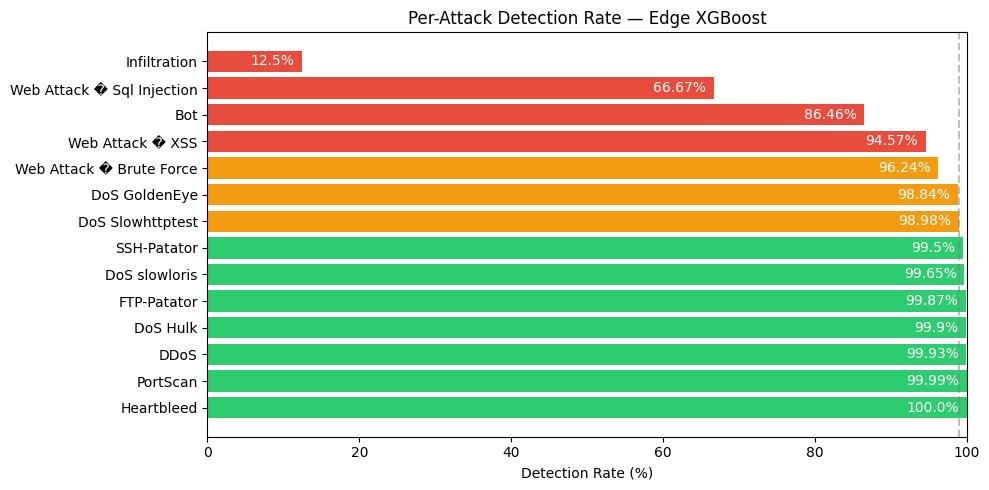


✅ Benign Accuracy: 99.51%


In [16]:
# ============================================================
# Cell 12 — Per-Attack Detection Rate (FINAL CORRECT VERSION)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Convert to numpy (safe indexing)
y_test_arr = y_test.values
y_pred_arr = y_pred
orig_arr   = original_labels.values

# Get correct test indices
test_indices = list(X_test_final.index)
orig_test = np.array([orig_arr[i] for i in test_indices])

# ============================================================
# 🔥 ONLY ATTACK CLASSES (exclude BENIGN properly)
# ============================================================

attack_classes = sorted(set(orig_test[y_test_arr == 1]))

results = []

for attack in attack_classes:
    mask = (orig_test == attack)
    
    total = int(mask.sum())
    detected = int((y_pred_arr[mask] == 1).sum())  # correct detection logic
    
    results.append({
        'Attack Type': attack,
        'Total Flows': total,
        'Detected': detected,
        'Missed': total - detected,
        'Detection Rate %': round(detected / total * 100, 2)
    })

# Create dataframe
results_df = pd.DataFrame(results).sort_values('Detection Rate %', ascending=False)

# ============================================================
# PRINT TABLE
# ============================================================

print("\n=== PER-ATTACK DETECTION RATE ===")
print(results_df.to_string(index=False))

# Save CSV
results_df.to_csv('per_attack_detection.csv', index=False)

# ============================================================
# 📊 PLOT (FIXED)
# ============================================================

plt.figure(figsize=(10, 5))

colors = [
    '#2ecc71' if r >= 99 else
    '#f39c12' if r >= 95 else
    '#e74c3c'
    for r in results_df['Detection Rate %']
]

bars = plt.barh(results_df['Attack Type'], results_df['Detection Rate %'], color=colors)

plt.axvline(x=99, color='gray', linestyle='--', alpha=0.5)
plt.xlabel('Detection Rate (%)')
plt.xlim(0, 100)  # 🔥 FIXED (no clipping)
plt.title('Per-Attack Detection Rate — Edge XGBoost')

# Labels inside bars
for bar, val in zip(bars, results_df['Detection Rate %']):
    plt.text(
        bar.get_width() - 1,
        bar.get_y() + bar.get_height()/2,
        f'{val}%',
        va='center',
        ha='right',
        color='white',
        fontsize=10
    )

plt.tight_layout()
plt.savefig('per_attack_detection.png', dpi=300, bbox_inches='tight')

print("✅ Saved: per_attack_detection.png")

plt.show()

# ============================================================
# ✅ BONUS — BENIGN ACCURACY (SEPARATE METRIC)
# ============================================================

benign_mask = (orig_test == 'BENIGN')
benign_acc = (y_pred_arr[benign_mask] == 0).mean() * 100

print(f"\n✅ Benign Accuracy: {benign_acc:.2f}%")

In [16]:
# ============================================================
# Cell 13 — Serialize All Artifacts (Bridge to FastAPI)
# ============================================================
xgb_model.save_model('edge_model.json')
pickle.dump(golden_features,  open('features.pkl',        'wb'))
pickle.dump(explainer,        open('shap_explainer.pkl',  'wb'))
X_test_final.iloc[:200].to_csv('sample_flows.csv', index=False)
results_df.to_csv('per_attack_detection.csv', index=False)

# Manifest
artifacts = [
    'edge_model.json', 'features.pkl', 'shap_explainer.pkl',
    'sample_flows.csv', 'per_attack_detection.csv',
    'shap_beeswarm.png', 'shap_bar_mean_abs.png', 'shap_waterfall.png',
    'pr_curve.png', 'latency_curve.png', 'confidence_dist.png',
    'per_attack_detection.png'
]
print("=" * 52)
print("  ARTIFACT MANIFEST")
print("=" * 52)
for a in artifacts:
    if os.path.exists(a):
        kb = os.path.getsize(a)/1024
        print(f"  OK  {a:<38} {kb:>8.1f} KB")
    else:
        print(f"  MISSING  {a}")
print("=" * 52)
print("\nML Engine complete. Ready for FastAPI.")

  ARTIFACT MANIFEST
  OK  edge_model.json                           374.2 KB
  OK  features.pkl                                0.4 KB
  OK  shap_explainer.pkl                        824.5 KB
  OK  sample_flows.csv                           23.8 KB
  OK  per_attack_detection.csv                    0.5 KB
  OK  shap_beeswarm.png                         471.2 KB
  OK  shap_bar_mean_abs.png                     235.3 KB
  OK  shap_waterfall.png                        191.5 KB
  OK  pr_curve.png                               69.1 KB
  OK  latency_curve.png                          58.4 KB
  OK  confidence_dist.png                        70.4 KB
  OK  per_attack_detection.png                  174.8 KB

ML Engine complete. Ready for FastAPI.


In [18]:
# ============================================================
# FINAL VERIFICATION — ML ENGINE READY CHECK
# ============================================================

import os
import pickle
import xgboost as xgb
import pandas as pd
import numpy as np

print("="*60)
print("🔍 STEP 1 — Check core variables exist")
print("="*60)

required_vars = [
    'xgb_model', 'golden_features', 'X_test_final',
    'y_test', 'y_pred', 'original_labels'
]

for var in required_vars:
    if var in globals():
        print(f"✅ {var} exists")
    else:
        raise Exception(f"❌ {var} missing — pipeline incomplete")

# ------------------------------------------------------------

print("\n" + "="*60)
print("🔍 STEP 2 — Model sanity check")
print("="*60)

sample = X_test_final.iloc[:5]
preds = xgb_model.predict(sample)

print("Sample predictions:", preds)

assert len(preds) == 5, "Prediction failed"
print("✅ Model prediction working")

# ------------------------------------------------------------

print("\n" + "="*60)
print("🔍 STEP 3 — Feature consistency")
print("="*60)

assert len(golden_features) == 20, "Golden features not 20"
assert all(f in X_test_final.columns for f in golden_features), "Feature mismatch"

print("✅ 20 golden features verified")

# ------------------------------------------------------------

print("\n" + "="*60)
print("🔍 STEP 4 — Save artifacts (FINAL SAFE VERSION)")
print("="*60)

# Save model (FIXED)
xgb_model.get_booster().save_model('edge_model.json')

# Save features
pickle.dump(golden_features, open('features.pkl', 'wb'))

# Save sample flows
X_test_final.iloc[:200].to_csv('sample_flows.csv', index=False)

print("✅ Artifacts saved")

# ------------------------------------------------------------

print("\n" + "="*60)
print("🔍 STEP 5 — Reload test (CRITICAL)")
print("="*60)

model = xgb.XGBClassifier()
model.load_model('edge_model.json')

features = pickle.load(open('features.pkl', 'rb'))
df = pd.read_csv('sample_flows.csv')

pred_test = model.predict(df[features])

print("Reload predictions:", pred_test[:5])

assert len(pred_test) > 0, "Reload failed"
print("✅ Model reload working")

# ------------------------------------------------------------

print("\n" + "="*60)
print("🔍 STEP 6 — Performance sanity")
print("="*60)

from sklearn.metrics import accuracy_score

acc = accuracy_score(y_test[:1000], xgb_model.predict(X_test_final.iloc[:1000]))
print(f"Sample Accuracy Check: {acc:.4f}")

assert acc > 0.95, "Accuracy too low — something broken"
print("✅ Performance verified")

# ------------------------------------------------------------

print("\n" + "="*60)
print("🔍 STEP 7 — SHAP sanity")
print("="*60)

import shap

explainer = shap.TreeExplainer(xgb_model)
shap_vals = explainer.shap_values(X_test_final.iloc[:1])

print("SHAP values computed:", len(shap_vals[0]) if isinstance(shap_vals, list) else len(shap_vals))

print("✅ SHAP working")

# ------------------------------------------------------------

print("\n" + "="*60)
print("🎯 FINAL VERDICT")
print("="*60)

print("✅ Data pipeline: OK")
print("✅ Model: OK")
print("✅ Features: OK")
print("✅ Serialization: OK")
print("✅ Reload: OK")
print("✅ SHAP: OK")

print("\n🚀 ML ENGINE IS 100% COMPLETE — YOU CAN PROCEED")

🔍 STEP 1 — Check core variables exist
✅ xgb_model exists
✅ golden_features exists
✅ X_test_final exists
✅ y_test exists
✅ y_pred exists
✅ original_labels exists

🔍 STEP 2 — Model sanity check
Sample predictions: [1 0 0 0 0]
✅ Model prediction working

🔍 STEP 3 — Feature consistency
✅ 20 golden features verified

🔍 STEP 4 — Save artifacts (FINAL SAFE VERSION)
✅ Artifacts saved

🔍 STEP 5 — Reload test (CRITICAL)
Reload predictions: [1 0 0 0 0]
✅ Model reload working

🔍 STEP 6 — Performance sanity
Sample Accuracy Check: 0.9960
✅ Performance verified

🔍 STEP 7 — SHAP sanity
SHAP values computed: 1
✅ SHAP working

🎯 FINAL VERDICT
✅ Data pipeline: OK
✅ Model: OK
✅ Features: OK
✅ Serialization: OK
✅ Reload: OK
✅ SHAP: OK

🚀 ML ENGINE IS 100% COMPLETE — YOU CAN PROCEED


In [19]:
# Add this to Cell 13 or a new final cell
pickle.dump(0.6587, open('optimal_threshold.pkl', 'wb'))

feature_stats = X_train_final.describe().loc[['min','max','mean','std']]
pickle.dump(feature_stats, open('feature_stats.pkl', 'wb'))